# Avrupa'da sosyal ağ kullanımı, 2014–2025: Türkiye nerede?
**Çalışma sorusu:** Türkiye'de sosyal ağ kullanımı 2014–2025 arasında AB ortalamasına ve diğer Avrupa ülkelerine göre nasıl değişti?

**Veri:** Eurostat, *Individuals using the internet for participating in social networks* (`tin00127`). 16–74 yaş bireylerin son 3 ayda özel amaçla sosyal ağ kullanım oranı (%). Kaynak: Eurostat yıllık BİT hane halkı anketi. Erişim: 12.10.2026.

**Akış:** veri yükleme → temizleme → keşifsel analiz → bulgular → site için özet dosyaların üretimi.

In [1]:
import json, shutil
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
RAW = Path("../data/raw/tin00127_page_spreadsheet.xlsx")
OUT = Path("../data/processed"); OUT.mkdir(parents=True, exist_ok=True)
SITE = Path("../site/data"); SITE.mkdir(parents=True, exist_ok=True)
ACC, INK, GRY = "#D55E00", "#1b1b1f", "#7a7a82"   # sitedeki palet ile aynı

## 1. Veri yükleme
Eurostat dosyası `Sheet 1` sayfasında **geniş** biçimde: her yılın yanında bir *bayrak* sütunu var (ör. `b` = seri kesintisi). Üst bilgi satırlarını ve ülke bloğunun yerini sabit numara yerine başlık metninden buluyoruz.

In [2]:
raw = pd.read_excel(RAW, sheet_name="Sheet 1", header=None)
print(raw.iloc[0,0]); print(raw.iloc[1,0], raw.iloc[1,1]); print(raw.iloc[2,0], raw.iloc[2,1])
hdr = raw.index[raw[0] == "TIME"][0]
years = [int(y) for y in raw.iloc[hdr, 1:].dropna()]
start = raw.index[raw[0] == "GEO (Labels)"][0] + 1
end = raw.iloc[start:].index[raw.iloc[start:, 0].isna().values][0]
block = raw.iloc[start:end]
print("Yıllar:", years[0], "-", years[-1], "| ülke/bölge satırı:", len(block))

Data extracted on 12/10/2026 10:22:30 from [ESTAT]
Dataset:  Individuals using the internet for participating in social networks [tin00127]
Last updated:  17/04/2026 11:00
Yıllar: 2014 - 2025 | ülke/bölge satırı: 43


/usr/local/lib/python3.12/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


## 2. Temizleme
Her gözlem için **değer** ve **bayrak** sütunlarını ayırıp *uzun (tidy)* tabloya çeviriyoruz. `:` Eurostat'ta "veri yok" demektir; sayıya çevrilemediği için eksik (`NaN`) olur. Tahmin ya da doldurma yapmıyoruz.

In [3]:
recs = []
for _, r in block.iterrows():
    for i, y in enumerate(years):
        v = pd.to_numeric(r[1 + 2*i], errors="coerce")
        f = r[2 + 2*i]
        recs.append((r[0], y, v, f.strip() if isinstance(f, str) else ""))
df = pd.DataFrame(recs, columns=["geo", "year", "value", "flag"])
print("Toplam hücre:", len(df), "| eksik:", df.value.isna().sum(), f"(%{df.value.isna().mean()*100:.1f})")

Toplam hücre: 516 | eksik: 89 (%17.2)


### Temizleme kararları ve gerekçeleri
1. **Euro bölgesi serileri çıkarıldı.** Üç ayrı euro bölgesi satırı (19/20/21 ülke) var, ancak hepsi tamamen eksik. Doldurulacak veri yok.
2. **Liechtenstein çıkarıldı.** Hiçbir yılda verisi yok.
3. **AB-27 ortalaması ayrı seri olarak tutuldu.** Ülke sıralamalarına karıştırılmayacak, referans çizgisi olacak.
4. **Kısmi verisi olan ülkeler (İzlanda, İsviçre, Birleşik Krallık, Kosova vb.) tutuldu**, ama karşılaştırmalar yalnızca ilgili iki yılın verisi olan ülkelerle yapılacak. Böylece sıralama, yıllar arasında farklı ülke kümelerini karıştırmaz.
5. **Aykırı değer silinmedi.** Anket verisinde büyük sıçramalar gerçek olabilir; aşağıda kontrol ediyoruz ve kesinti (`b`) bayraklarıyla birlikte not ediyoruz.

In [4]:
euro = df[df.geo.str.startswith("Euro area")]
assert euro.value.isna().all(), "Euro bölgesi satırlarında veri var, karar gözden geçirilmeli"
tidy = df[~df.geo.str.startswith("Euro area")].copy()
tidy["geo"] = tidy.geo.replace({"European Union - 27 countries (from 2020)": "EU27"})
allmiss = tidy.groupby("geo").value.apply(lambda s: s.isna().all())
print("Tamamen eksik olanlar:", list(allmiss[allmiss].index))
tidy = tidy[~tidy.geo.isin(allmiss[allmiss].index)]
print("Kalan ülke/seri sayısı:", tidy.geo.nunique())
tidy.groupby("geo").value.count().sort_values().head(8)

Tamamen eksik olanlar: ['Liechtenstein']
Kalan ülke/seri sayısı: 39


geo
Kosovo*                    6
Iceland                    6
Switzerland                6
Bosnia and Herzegovina     7
United Kingdom             7
Albania                    8
Montenegro                 9
North Macedonia           10
Name: value, dtype: int64

In [5]:
w = tidy.pivot(index="geo", columns="year", values="value")
d = w.diff(axis=1).stack()
print(d[d.abs() > 12].round(1).rename("değişim (puan)").to_string())
print("\nKesinti (b) bayraklı gözlem sayısı:", (tidy.flag == "b").sum())
print(tidy[tidy.flag == "b"].groupby("geo").year.apply(list).to_string())

geo       year
Belgium   2015    14.3
          2021   -16.1
Germany   2015    14.6
Kosovo*   2020    15.1
Slovenia  2020    15.0

Kesinti (b) bayraklı gözlem sayısı: 13
geo
Belgium              [2021]
Czechia              [2018]
EU27                 [2021]
Estonia              [2014]
France               [2025]
Germany              [2021]
Ireland              [2021]
Latvia               [2016]
Luxembourg           [2018]
Romania              [2014]
Sweden               [2016]
Switzerland    [2017, 2021]


**Karar:** 12 puandan büyük yıllık değişim 5 gözlemde var. Yalnızca Belçika 2021 düşüşü kesinti (`b`) bayraklı; Belçika ve Almanya 2015, Kosova ve Slovenya 2020 sıçramaları bayraksız. Bunların hatalı olduğunu kanıtlayacak bir dayanak yok, bu yüzden **silmedik**; fakat bu ülkeler ana hikâyede kullanılmıyor ve sitede kesinti yılları (`breaks`) okuyucuya gösteriliyor. Türkiye'nin 2022'deki 10,8 puanlık sıçraması eşiğin altında ve bayraksız; nedeni bu veriyle açıklanamaz, sitede de öyle söylüyoruz.

In [6]:
tidy = tidy.dropna(subset=["value"]).reset_index(drop=True)
print(len(tidy), "gözlem,", tidy.geo.nunique(), "ülke/seri,", tidy.year.min(), "-", tidy.year.max())

427 gözlem, 39 ülke/seri, 2014 - 2025


## 3. Keşifsel analiz
### 3.1 AB-27 ortalaması ve Türkiye zaman içinde

In [7]:
w = tidy.pivot(index="geo", columns="year", values="value")
cmp = w.loc[["EU27", "Türkiye"]].T.round(1); cmp["fark"] = (cmp["Türkiye"] - cmp["EU27"]).round(1)
cmp

geo,EU27,Türkiye,fark
year,,,
2014,43.6,38.2,-5.4
2015,47.9,41.5,-6.4
2016,49.2,48.1,-1.1
2017,51.8,54.1,2.3
2018,53.7,59.8,6.1
2019,54.2,60.2,6.0
2020,57.3,62.3,5.0
2021,56.8,60.1,3.3
2022,58.1,70.8,12.7


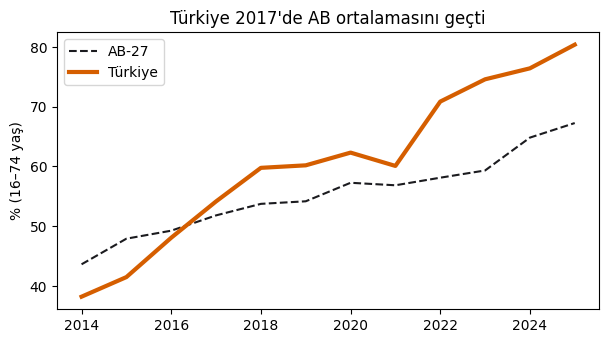

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(w.columns, w.loc["EU27"], "--", color=INK, label="AB-27")
ax.plot(w.columns, w.loc["Türkiye"], color=ACC, lw=3, label="Türkiye")
ax.set(ylabel="% (16–74 yaş)", title="Türkiye 2017'de AB ortalamasını geçti"); ax.legend(); plt.show()

### 3.2 2025 sıralaması
Sıralama yalnızca o yıl verisi olan ülkeleri kapsar (kaç ülke olduğu yıla göre değişir).

In [9]:
r25 = w[2025].drop("EU27").dropna().sort_values(ascending=False)
print(len(r25), "ülke"); r25.round(1).head(10).to_frame("2025 (%)")

36 ülke


,2025 (%)
geo,
Denmark,89.7
Norway,88.9
Cyprus,86.5
Montenegro,83.8
Kosovo*,83.2
Malta,82.4
Finland,81.3
Netherlands,81.2
Türkiye,80.4


### 3.3 Geriden başlayan daha çok arttı mı?
Her iki yılda da verisi olan ülkeler için 2014 düzeyi ile 2014→2025 değişimi (puan = iki yüzde arasındaki fark) karşılaştırılır. **Korelasyon** (r), iki değişkenin birlikte hareket etme derecesidir (−1…+1); nedensellik göstermez.

31 ülke | r = -0.55


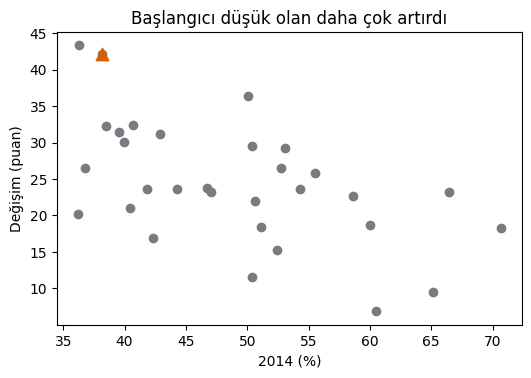

In [10]:
both = w[[2014, 2025]].dropna().drop("EU27")
both["degisim"] = both[2025] - both[2014]
r = np.corrcoef(both[2014], both["degisim"])[0, 1]
print(len(both), "ülke | r =", round(r, 2))
fig, ax = plt.subplots(figsize=(6, 3.8)); ax.scatter(both[2014], both.degisim, c=GRY)
ax.scatter(both.loc["Türkiye", 2014], both.loc["Türkiye", "degisim"], c=ACC, s=80, marker="^")
ax.set(xlabel="2014 (%)", ylabel="Değişim (puan)", title="Başlangıcı düşük olan daha çok artırdı"); plt.show()

### 3.4 Ülkeler birbirine yaklaştı mı?
Standart sapma, ülkelerin ortalamadan ne kadar saçıldığını gösterir.

In [11]:
sd14, sd25 = both[2014].std(), both[2025].std(); print(round(sd14, 1), "→", round(sd25, 1))

9.5 → 8.5


## 4. Bulgular ve doğrulama
Sitede kullanılacak tüm sayıları burada hesaplıyoruz; site bunları `facts.json` dosyasından okur, metne elle sayı yazılmaz. Hikâyedeki sözel iddialar ("ikiye katlandı", "AB'yi geçti") `assert` ile doğrulanır.

In [12]:
g = lambda c, y: float(w.loc[c, y])
eu, tr = w.loc["EU27"], w.loc["Türkiye"]
above = (tr > eu)
cross = int(next(y for y in years if above.loc[y:].all()))
rank25 = int(r25.rank(ascending=False)["Türkiye"])
F = dict(
  y0=years[0], y1=years[-1], eu14=round(g("EU27",2014),1), eu25=round(g("EU27",2025),1),
  tr14=round(g("Türkiye",2014),1), tr25=round(g("Türkiye",2025),1),
  eu_delta=round(g("EU27",2025)-g("EU27",2014),1), tr_delta=round(g("Türkiye",2025)-g("Türkiye",2014),1),
  tr_ratio=round(g("Türkiye",2025)/g("Türkiye",2014),1),
  gap14=int(round(g("EU27",2014)-g("Türkiye",2014))), gap25=int(round(g("Türkiye",2025)-g("EU27",2025))),
  cross_year=cross, cross_i=cross-years[0], cross_tr=round(g("Türkiye",cross),1), cross_eu=round(g("EU27",cross),1),
  tr20=round(g("Türkiye",2020),1), tr21=round(g("Türkiye",2021),1), tr22=round(g("Türkiye",2022),1),
  i20=2020-years[0], i21=2021-years[0], i22=2022-years[0],
  jump=round(g("Türkiye",2022)-g("Türkiye",2021),1),
  dk25=round(g("Denmark",2025),1), it25=round(g("Italy",2025),1),
  rank25=rank25, n25=int(len(r25)), r=round(float(r),2), n_both=int(len(both)),
  sd14=round(float(sd14),1), sd25=round(float(sd25),1),
  n_obs=int(len(tidy)), n_cells=int(len(df)), n_missing=int(df.value.isna().sum()), n_geo=int(tidy.geo.nunique()-1))
assert F["tr_ratio"] >= 2.0, "ikiye katlandı iddiası tutmuyor"
assert 75 <= F["tr25"] <= 85, "her 5 kişiden 4'ü iddiası tutmuyor"
assert F["tr14"] < F["eu14"] and F["tr25"] > F["eu25"], "AB'yi geçti iddiası"
assert F["tr21"] < F["tr20"] < F["tr22"], "2021 düşüş / 2022 sıçrama"
assert F["r"] < -0.3, "geriden başlayan daha çok arttı iddiası"
F

{'y0': 2014,
 'y1': 2025,
 'eu14': 43.6,
 'eu25': 67.3,
 'tr14': 38.2,
 'tr25': 80.4,
 'eu_delta': 23.7,
 'tr_delta': 42.2,
 'tr_ratio': 2.1,
 'gap14': 5,
 'gap25': 13,
 'cross_year': 2017,
 'cross_i': 3,
 'cross_tr': 54.1,
 'cross_eu': 51.8,
 'tr20': 62.3,
 'tr21': 60.1,
 'tr22': 70.8,
 'i20': 6,
 'i21': 7,
 'i22': 8,
 'jump': 10.8,
 'dk25': 89.7,
 'it25': 56.4,
 'rank25': 9,
 'n25': 36,
 'r': -0.55,
 'n_both': 31,
 'sd14': 9.5,
 'sd25': 8.5,
 'n_obs': 427,
 'n_cells': 516,
 'n_missing': 89,
 'n_geo': 38}

## 5. Site için özet dosyaların üretimi
Site ham veriyi değil, yalnızca bu küçük özet dosyaları kullanır (5 MB sınırının çok altında).

In [13]:
TR = {"EU27":"AB-27 ortalaması","Belgium":"Belçika","Bulgaria":"Bulgaristan","Czechia":"Çekya","Denmark":"Danimarka","Germany":"Almanya","Estonia":"Estonya","Ireland":"İrlanda","Greece":"Yunanistan","Spain":"İspanya","France":"Fransa","Croatia":"Hırvatistan","Italy":"İtalya","Cyprus":"Kıbrıs","Latvia":"Letonya","Lithuania":"Litvanya","Luxembourg":"Lüksemburg","Hungary":"Macaristan","Malta":"Malta","Netherlands":"Hollanda","Austria":"Avusturya","Poland":"Polonya","Portugal":"Portekiz","Romania":"Romanya","Slovenia":"Slovenya","Slovakia":"Slovakya","Finland":"Finlandiya","Sweden":"İsveç","Iceland":"İzlanda","Norway":"Norveç","Switzerland":"İsviçre","United Kingdom":"Birleşik Krallık","Montenegro":"Karadağ","North Macedonia":"Kuzey Makedonya","Albania":"Arnavutluk","Serbia":"Sırbistan","Türkiye":"Türkiye","Bosnia and Herzegovina":"Bosna-Hersek","Kosovo*":"Kosova*"}
missing = set(tidy.geo) - set(TR); assert not missing, missing
summary = {
  "years": years,
  "series": {TR[c]: [None if pd.isna(x) else round(float(x),1) for x in w.loc[c].reindex(years)] for c in w.index},
  "scatter": [{"c": TR[c], "x": round(float(both.loc[c,2014]),1), "y": round(float(both.loc[c,"degisim"]),1)} for c in both.index],
  "breaks": {TR[c]: sorted(map(int, g_.year)) for c, g_ in tidy[tidy.flag=="b"].groupby("geo")}}
tidy.assign(geo_tr=tidy.geo.map(TR)).to_csv(OUT/"tidy.csv", index=False)
(OUT/"summary.json").write_text(json.dumps(summary, ensure_ascii=False, separators=(",",":")), encoding="utf-8")
(OUT/"facts.json").write_text(json.dumps(F, ensure_ascii=False, indent=1), encoding="utf-8")
for f in ["summary.json", "facts.json"]: shutil.copy(OUT/f, SITE/f)
print({f.name: f.stat().st_size for f in OUT.iterdir()})

{'summary.json': 4308, 'facts.json': 514, 'tidy.csv': 12988}
